In [23]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [24]:
import pandas as pd

processed = "../data/processed"

X_train = pd.read_csv(f"{processed}/X_train_processed.csv")
X_test  = pd.read_csv(f"{processed}/X_test_processed.csv")
y_train = pd.read_csv(f"{processed}/y_train.csv")
y_test  = pd.read_csv(f"{processed}/y_test.csv")

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(763, 24) (191, 24) (763, 1) (191, 1)


In [25]:

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

model.fit(X_train, y_train)
print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [26]:
y_pred = model.predict(X_test)
print(y_pred)

[0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0 0 0 1 0 1 0 0
 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0]


In [27]:
from sklearn.metrics import classification_report

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6701570680628273

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.86      0.78       133
           1       0.42      0.22      0.29        58

    accuracy                           0.67       191
   macro avg       0.57      0.54      0.54       191
weighted avg       0.63      0.67      0.64       191



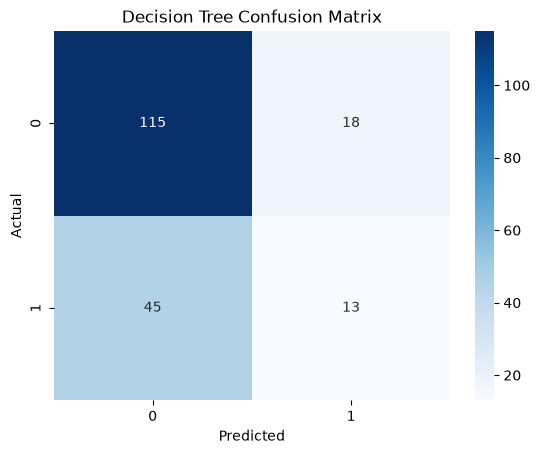

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [29]:
importance = model.feature_importances_

feature_names = X_train.columns

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                                     Feature  Importance
2                     numeric__Credit amount    0.334113
3                          numeric__Duration    0.282500
13      categorical__Checking account_little    0.098156
19            categorical__Purpose_education    0.087742
7                   categorical__Housing_own    0.085672
1                               numeric__Job    0.059621
0                               numeric__Age    0.047696
6                  categorical__Housing_free    0.004499
4                    categorical__Sex_female    0.000000
5                      categorical__Sex_male    0.000000
10     categorical__Saving accounts_moderate    0.000000
8                  categorical__Housing_rent    0.000000
11   categorical__Saving accounts_quite rich    0.000000
12         categorical__Saving accounts_rich    0.000000
14    categorical__Checking account_moderate    0.000000
9        categorical__Saving accounts_little    0.000000
15        categorical__Checking

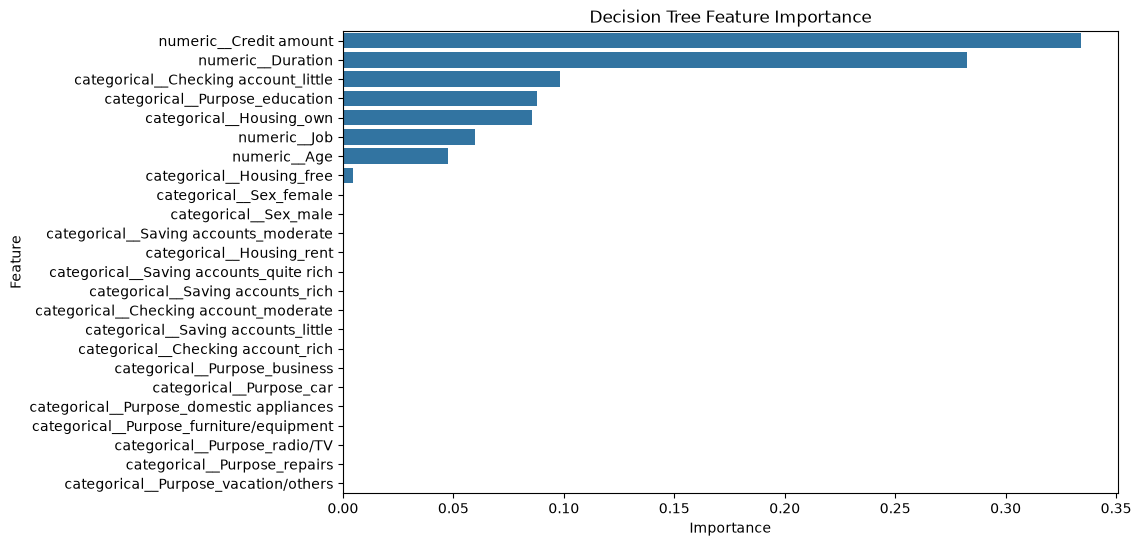

In [30]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Decision Tree Feature Importance")
plt.show()

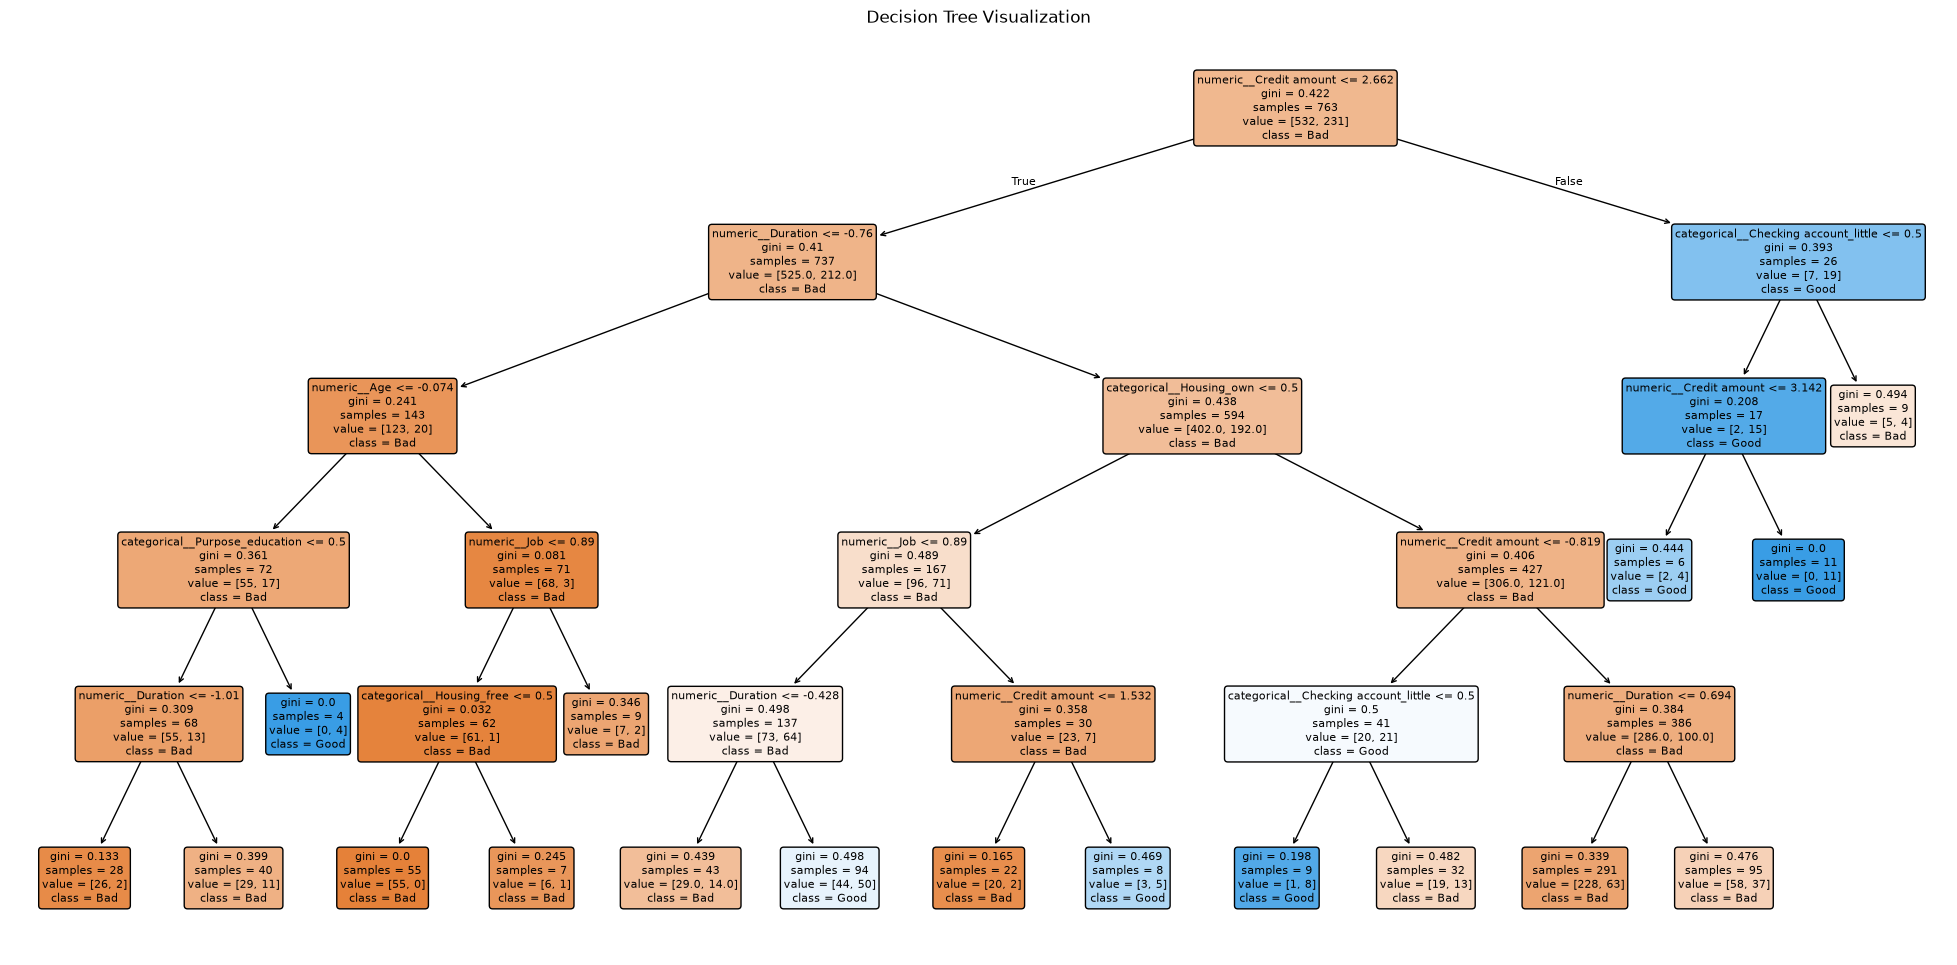

In [31]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25,12))

plot_tree(
    model,
    feature_names=X_train.columns,
    class_names=["Bad", "Good"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

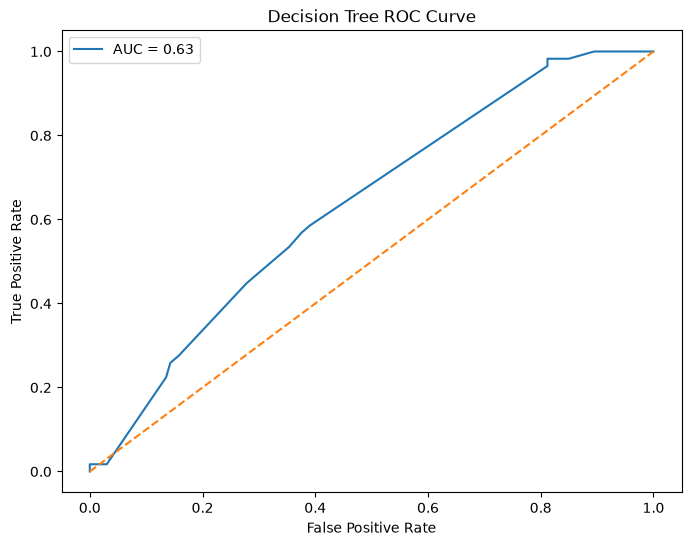

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")

plt.legend()
plt.show()

In [41]:
parameters = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", grid.best_score_)

Best Parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best CV F1 Score: 0.4538547709869281


In [42]:
y_pred_tuned = best_model.predict(X_test)

print(classification_report(y_test, y_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.80      0.43      0.56       133
           1       0.37      0.76      0.49        58

    accuracy                           0.53       191
   macro avg       0.58      0.59      0.53       191
weighted avg       0.67      0.53      0.54       191

Confusion Matrix:
[[57 76]
 [14 44]]


In [35]:
print("Original Model Accuracy:",
      accuracy_score(y_test, model.predict(X_test)))

print("Tuned Model Accuracy:",
      accuracy_score(y_test, best_model.predict(X_test)))

Original Model Accuracy: 0.6701570680628273
Tuned Model Accuracy: 0.6910994764397905


In [38]:

# Predictions using tuned model
y_pred_tuned = best_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_tuned)

precision = precision_score(y_test, y_pred_tuned, average="weighted")

recall = recall_score(y_test, y_pred_tuned, average="weighted")

f1 = f1_score(y_test, y_pred_tuned, average="weighted")

# Display results
print("TUNED DECISION TREE MODEL PERFORMANCE")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

TUNED DECISION TREE MODEL PERFORMANCE
Accuracy: 0.6910994764397905
Precision: 0.48376963350785346
Recall: 0.6910994764397905
F1 Score: 0.5691407453033569

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.99      0.82       133
           1       0.00      0.00      0.00        58

    accuracy                           0.69       191
   macro avg       0.35      0.50      0.41       191
weighted avg       0.48      0.69      0.57       191


Confusion Matrix:
[[132   1]
 [ 58   0]]


In [37]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],

    "Original Model": [
        accuracy_score(y_test, model.predict(X_test)),
        precision_score(y_test, model.predict(X_test), average="weighted"),
        recall_score(y_test, model.predict(X_test), average="weighted"),
        f1_score(y_test, model.predict(X_test), average="weighted")
    ],

    "Tuned Model": [
        accuracy_score(y_test, best_model.predict(X_test)),
        precision_score(y_test, best_model.predict(X_test), average="weighted"),
        recall_score(y_test, best_model.predict(X_test), average="weighted"),
        f1_score(y_test, best_model.predict(X_test), average="weighted")
    ]
})

print(results)

      Metric  Original Model  Tuned Model
0   Accuracy        0.670157     0.691099
1  Precision        0.627834     0.483770
2     Recall        0.670157     0.691099
3   F1 Score        0.635322     0.569141


In [39]:
from sklearn.metrics import classification_report

print("ORIGINAL MODEL")
print(classification_report(y_test, model.predict(X_test)))

print("TUNED MODEL")
print(classification_report(y_test, best_model.predict(X_test)))

ORIGINAL MODEL
              precision    recall  f1-score   support

           0       0.72      0.86      0.78       133
           1       0.42      0.22      0.29        58

    accuracy                           0.67       191
   macro avg       0.57      0.54      0.54       191
weighted avg       0.63      0.67      0.64       191

TUNED MODEL
              precision    recall  f1-score   support

           0       0.69      0.99      0.82       133
           1       0.00      0.00      0.00        58

    accuracy                           0.69       191
   macro avg       0.35      0.50      0.41       191
weighted avg       0.48      0.69      0.57       191



In [40]:
print("Original Confusion Matrix:")
print(confusion_matrix(y_test, model.predict(X_test)))

print("Tuned Confusion Matrix:")
print(confusion_matrix(y_test, best_model.predict(X_test)))

Original Confusion Matrix:
[[115  18]
 [ 45  13]]
Tuned Confusion Matrix:
[[132   1]
 [ 58   0]]


In [43]:
print("Target classes:", best_model.classes_)
print(y_train.value_counts())

Target classes: [0 1]
Credit Risk
0              532
1              231
Name: count, dtype: int64
